In [1]:
print("ANN Assignment 3 is starting")

ANN Assignment 3 is starting


***Import libraries and load the dataset***

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

# Connect Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Load dataset
file_path = '/content/drive/MyDrive/Churn_Modelling.csv'
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

TensorFlow version: 2.21.0
Mounted at /content/drive
Dataset loaded successfully!
Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


***Explore and prepare the dataset***

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df['Exited'].value_counts())

# Separate features and target
X = df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname', 'Exited']
)
y = df['Exited']

# Convert categorical features into numeric columns
X = pd.get_dummies(
    X,
    columns=['Geography', 'Gender'],
    drop_first=True,
    dtype=int
)

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)
print("\nEncoded feature columns:")
print(X.columns.tolist())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing values:
0

Target distribution:
Exited
0    7963
1    2037
Name:

***Split the data and normalize it***

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train_scaled.shape[0])
print("Testing samples:", X_test_scaled.shape[0])
print("Number of input features:", X_train_scaled.shape[1])

Training samples: 8000
Testing samples: 2000
Number of input features: 11


***Build the initial ANN model***

In [5]:
tf.random.set_seed(42)

model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

***Train the initial model***

In [6]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7934 - loss: 0.4963 - val_accuracy: 0.7987 - val_loss: 0.4479
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7998 - loss: 0.4404 - val_accuracy: 0.8050 - val_loss: 0.4359
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8069 - loss: 0.4296 - val_accuracy: 0.8138 - val_loss: 0.4295
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8114 - loss: 0.4217 - val_accuracy: 0.8225 - val_loss: 0.4227
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8189 - loss: 0.4140 - val_accuracy: 0.8294 - val_loss: 0.4141
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8252 - loss: 0.4051 - val_accuracy: 0.8394 - val_loss: 0.4040
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8322 - loss: 0.3963 - val_accuracy: 0.8425 - val_loss: 0.3937
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8375 - loss: 0.3880 - val_accuracy: 0.

***Improve the model***

In [7]:
tf.random.set_seed(42)

improved_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(16, activation='relu'),
    Dropout(0.2),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

improved_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

improved_history = improved_model.fit(
    X_train_scaled,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7953 - loss: 0.5069 - val_accuracy: 0.8000 - val_loss: 0.4521
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4546 - val_accuracy: 0.8000 - val_loss: 0.4343
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4435 - val_accuracy: 0.8000 - val_loss: 0.4293
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4384 - val_accuracy: 0.8000 - val_loss: 0.4238
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4300 - val_accuracy: 0.8000 - val_loss: 0.4166
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4246 - val_accuracy: 0.8000 - val_loss: 0.4112
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4177 - val_accuracy: 0.8000 - val_loss: 0.4051
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7953 - loss: 0.4131 - val_accuracy: 0.

***Evaluate accuracy and confusion matrix***

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
ANN Test Accuracy: 0.8615

Classification Report:
              precision    recall  f1-score   support

       Stays       0.87      0.97      0.92      1593
      Leaves       0.79      0.43      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.84      2000

Confusion Matrix:
[[1547   46]
 [ 231  176]]


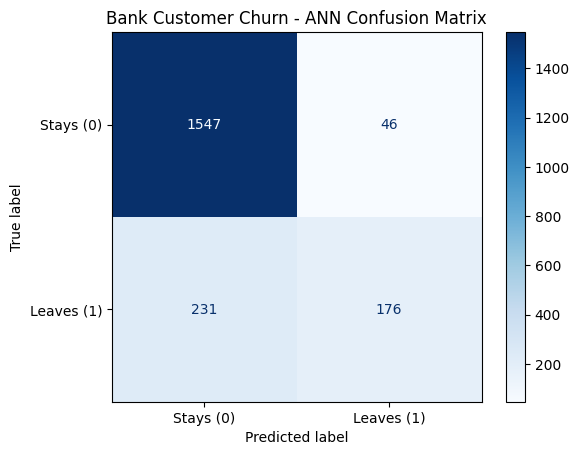

In [8]:
# Predict customer churn probabilities
y_probability = improved_model.predict(X_test_scaled)

# Convert probabilities into classes
y_pred = (y_probability >= 0.5).astype(int).ravel()

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("ANN Test Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Stays', 'Leaves']
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Stays (0)', 'Leaves (1)']
)

disp.plot(cmap='Blues')
plt.title('Bank Customer Churn - ANN Confusion Matrix')
plt.show()

***Plot training and validation accuracy***

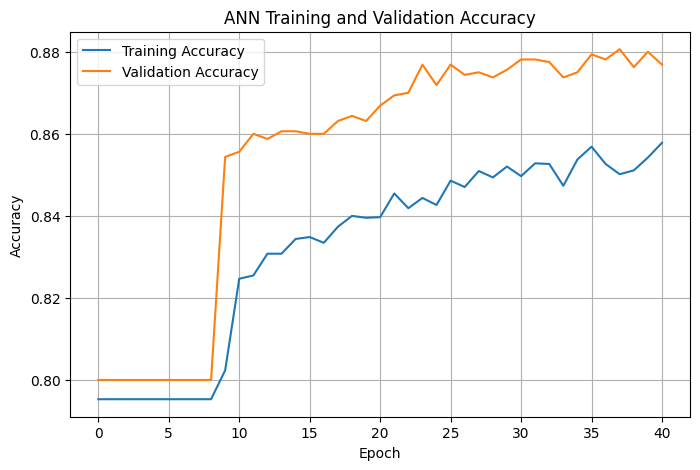

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    improved_history.history['accuracy'],
    label='Training Accuracy'
)
plt.plot(
    improved_history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ANN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

***Compare the initial and improved models***

In [10]:
initial_loss, initial_accuracy = model.evaluate(
    X_test_scaled, y_test, verbose=0
)

improved_loss, improved_accuracy = improved_model.evaluate(
    X_test_scaled, y_test, verbose=0
)

comparison = pd.DataFrame({
    'Model': ['Initial ANN', 'Improved ANN'],
    'Test Accuracy': [initial_accuracy, improved_accuracy],
    'Test Loss': [initial_loss, improved_loss]
})

display(comparison.round(4))

,Model,Test Accuracy,Test Loss
0,Initial ANN,0.8625,0.3391
1,Improved ANN,0.8615,0.3449
